# Lempel-Ziv (LZ) Complexity in Quantitative Finance
## 1. Historical Background
### 1.1 The Lempel-Ziv Algorithm (1976)
Developed by Abraham Lempel and Jacob Ziv in 1976, **Lempel-Ziv (LZ)** is a universal data compression algorithm. While originally intended for lossless data compression (powering modern formats like ZIP, GIF, and PNG), researchers later realized that its ability to compress a sequence perfectly correlates with the **predictability** and **entropy** of that sequence.

In quantitative finance, if a time series can be highly compressed by LZ, it means the sequence contains repeating patterns, trends, and structure (low complexity). If it cannot be compressed, it resembles pure noise (high complexity).

### 1.2 Information Theory & Markets
The Adaptive Markets Hypothesis (AMH) states that markets oscillate between periods of efficiency (randomness) and inefficiency (trends/patterns). Lempel-Ziv complexity gives us a direct, model-free mathematical lens to quantify exactly *how random* the market is at any given moment.

## 2. Interpreting Lempel-Ziv Complexity
Unlike the Hurst Exponent which measures long-memory and fractals over strict distributions, LZ Complexity works on discrete symbols (usually binary 0s and 1s) and measures sheer pattern repetition.

*   **Low LZ Complexity ($LZ 	o 0$):** The series is highly structured, predictable, and repetitive. (Trending or Mean-Reverting regimes).
*   **High LZ Complexity ($LZ 	o 1$):** The series is highly unpredictable, complex, and random. (Efficient Market regime).

## 3. Binarization of Financial Data
Because the classic LZ76 algorithm operates on binary strings, financial time series (like continuous price returns) must first be converted into a sequence of binary digits ($0$ or $1$). 

Common binarization techniques:
*   **Mean-Return Threshold:** 1 if $r_t > \mu$, else 0.
*   **Zero-Threshold (Directional):** 1 if $r_t > 0$ (Up day), else 0 (Down day).
*   **Volatility-Threshold:** 1 if $|r_t| > \sigma$ (High Vol regime), else 0.


# Part II — Code: Computing Lempel-Ziv Complexity
## 4. The LZ76 Algorithm from Scratch
The standard LZ76 complexity definition involves scanning a string from left to right and counting the number of *unique substrings* that have not appeared previously.

Let's implement the core `lz_complexity` function in Python.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

def lz_complexity(binary_string):
    """
    Computes the Lempel-Ziv (LZ76) complexity of a binary string.
    """
    if len(binary_string) == 0: return 0
    
    i, k, l = 0, 1, 1
    complexity = 1
    n = len(binary_string)
    
    while True:
        if i + k > n: break
        
        # Searching for the current substring in the history
        substring = binary_string[i:i+k]
        history = binary_string[0:i+k-1]
        
        if substring in history:
            k += 1
        else:
            complexity += 1
            i += k
            k = 1
            
    return complexity


c:\Users\vansh\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.2) or chardet (6.0.0.post1)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


### 5. Normalizing Lempel-Ziv Complexity
The raw LZ score simply counts the number of unique patterns. To be useful across different rolling window sizes, we must normalize it.

The theoretical maximum complexity for a completely random binary string of length $n$ is famously bound by:
$$C_{max}(n) = \frac{n}{\log_2 n}$$

Therefore, the **Normalized LZ Complexity** ($LZ_{norm}$) is:
$$LZ_{norm} = \frac{C_{raw}(n)}{C_{max}(n)}$$

Let's implement this normalizer.


In [2]:
def normalized_lz(binary_string):
    """
    Normalized Lempel-Ziv complexity bounded between roughly ~0.0 and ~1.0.
    Values near 1 imply a highly random sequence.
    Values near 0 imply a highly structured, predictable sequence.
    """
    n = len(binary_string)
    if n < 2: return 0
    
    raw_c = lz_complexity(binary_string)
    max_c = n / np.log2(n)
    
    norm_c = raw_c / max_c
    return norm_c


## 6. Verification on Synthetic Data
Before applying it to the S&P 500, let's verify that LZ behaves as expected on a completely structured array (Sine wave) vs a completely random array.


Structured (Sine Wave) LZ Complexity: 0.0598
Random (White Noise) LZ Complexity:   1.0464


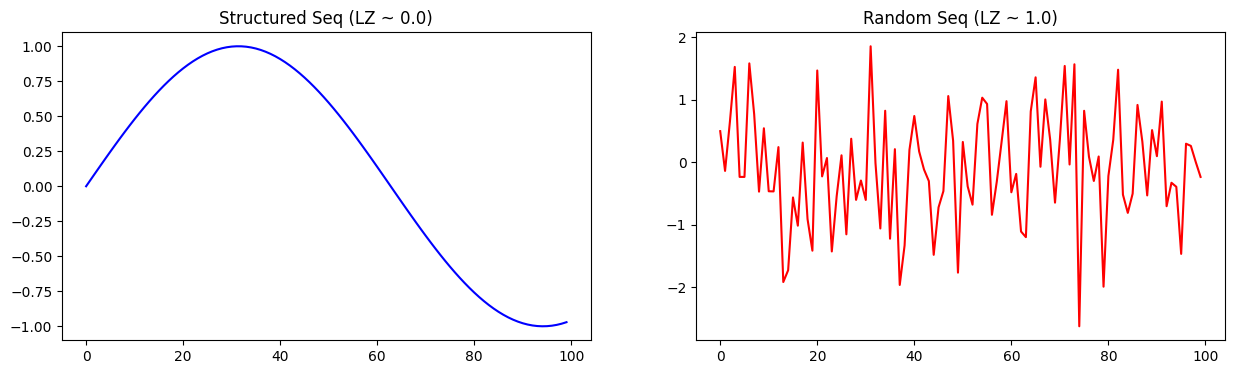

In [3]:
# 1. Perfectly Structured (Trending/Oscillating)
t = np.linspace(0, 50, 1000)
sine_wave = np.sin(t)
# Binarize: above mean = 1, below mean = 0
sine_binary = "".join(['1' if x > 0 else '0' for x in sine_wave])

# 2. Perfectly Random (White Noise)
np.random.seed(42)
white_noise = np.random.normal(0, 1, 1000)
# Binarize
noise_binary = "".join(['1' if x > 0 else '0' for x in white_noise])

print(f"Structured (Sine Wave) LZ Complexity: {normalized_lz(sine_binary):.4f}")
print(f"Random (White Noise) LZ Complexity:   {normalized_lz(noise_binary):.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4))
ax1.plot(sine_wave[:100], color='blue')
ax1.set_title(f'Structured Seq (LZ ~ 0.0)')
ax2.plot(white_noise[:100], color='red')
ax2.set_title(f'Random Seq (LZ ~ 1.0)')
plt.show()


# Part III — Real-World Financial Application
## 7. Rolling LZ Complexity on Market Data
To use LZ complexity in algorithmic trading, we calculate it dynamically over a rolling window. This transforms it into an indicator that flags when the market is entering a "predictable" regime versus a "random" regime.

Let's fetch the S&P 500 ETF (SPY) historical prices and compute rolling bounds.


In [4]:
# Fetch SPY Data
data = yf.download('SPY', start='2000-01-01', end='2023-01-01', progress=False)

# Due to Yahoo Finance changes, data might have MultiIndex columns. Clean them if necessary.
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

df = pd.DataFrame()
df['Close'] = data['Close']
df['Returns'] = df['Close'].pct_change()
df = df.dropna()

# 1. Binarize the Returns (Directional: Up = 1, Down = 0)
df['Binary'] = (df['Returns'] > 0).astype(int)

# 2. Compute Rolling Lempel-Ziv Complexity
window = 252 # 1 Trading Year

def rolling_lz(series):
    # Convert series to a single binary string, e.g. '1011001'
    b_str = "".join(series.astype(str).values)
    return normalized_lz(b_str)

print(f"Computing Rolling LZ Complexity for {len(df)} days. This may take a minute...")
# We use .rolling().apply() efficiently
df['Rolling_LZ'] = df['Binary'].rolling(window=window).apply(rolling_lz, raw=False)
df = df.dropna()
print("Calculation Complete!")


Computing Rolling LZ Complexity for 5786 days. This may take a minute...
Calculation Complete!


## 8. Identifying Information-Dense vs Random Regimes
Let's plot the Rolling LZ against the SPY price.
*   **High Complexity (LZ > 1.0):** Noise. Efficient market. Hard to trade.
*   **Low Complexity (LZ < 0.9):** High structure. Institutional trends. "Easy" to trade.


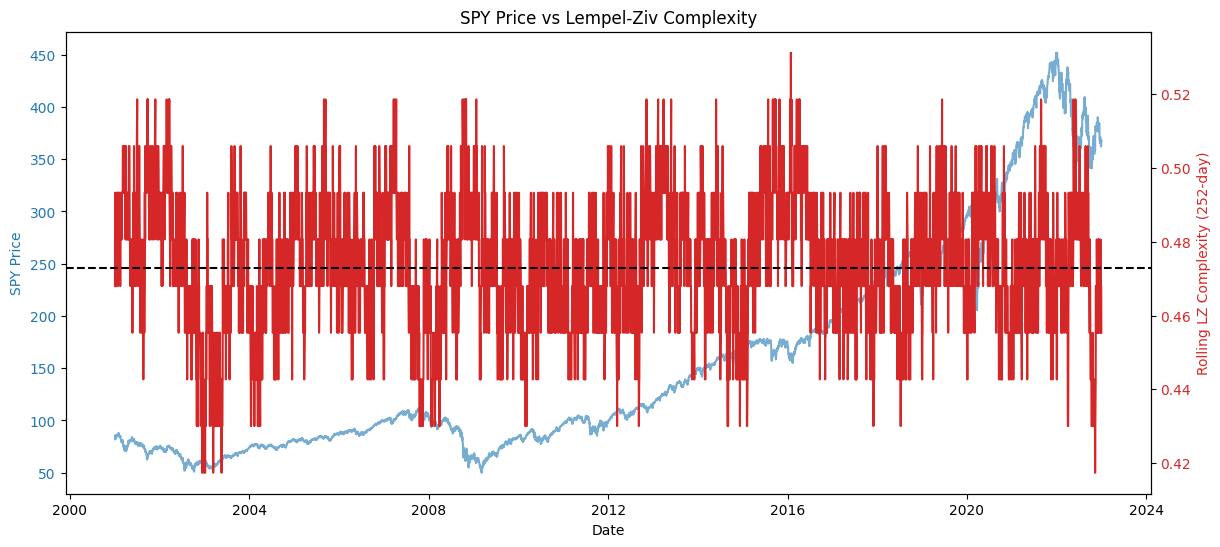

In [5]:
fig, ax1 = plt.subplots(figsize=(14, 6))

color = 'tab:blue'
ax1.set_xlabel('Date')
ax1.set_ylabel('SPY Price', color=color)
ax1.plot(df.index, df['Close'], color=color, alpha=0.6)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Rolling LZ Complexity (252-day)', color=color)
ax2.plot(df.index, df['Rolling_LZ'], color=color, linewidth=1.5)
ax2.axhline(df['Rolling_LZ'].mean(), color='black', linestyle='--', label='Mean LZ')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('SPY Price vs Lempel-Ziv Complexity')
plt.show()


# Part IV — Trading Strategy Application
## 9. LZ as a Regime Filter
Standard momentum moving-average crossover strategies fail dramatically in choppy, random markets. What if we use LZ Complexity as a **Regime Filter**?

**Strategy Rules:**
1.  **Core Signal:** Buy when the 50-day SMA crosses above the 200-day SMA. Sell when it crosses below.
2.  **LZ Filter:** ONLY execute the signal if the market is *predictable* ($LZ < Median LZ$). If the market is too random / complex over the last year, stay flat in Cash. 

Let's test this!


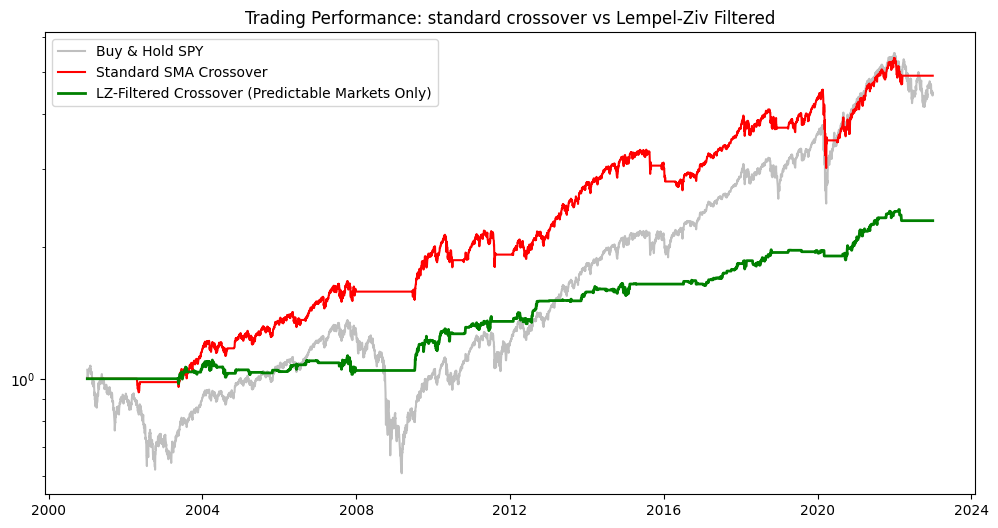

In [6]:
# 1. Generate core crossover signals
df['SMA_50'] = df['Close'].rolling(50).mean()
df['SMA_200'] = df['Close'].rolling(200).mean()

# Cross signal: 1 if SMA_50 > SMA_200, else 0
df['Cross_Signal'] = (df['SMA_50'] > df['SMA_200']).astype(int)

# 2. Generate LZ Filter
lz_median = df['Rolling_LZ'].median()
df['LZ_Filter'] = (df['Rolling_LZ'] < lz_median).astype(int) # 1 if predictable, 0 if random

# 3. Combined Strategy Position
df['Unfiltered_Position'] = df['Cross_Signal'].shift(1) # shift to avoid lookahead bias
df['Filtered_Position'] = (df['Cross_Signal'] * df['LZ_Filter']).shift(1)

# 4. Calculate Returns
df['Buy_Hold_Returns'] = df['Returns']
df['Unfiltered_Strategy_Returns'] = df['Unfiltered_Position'] * df['Returns']
df['Filtered_Strategy_Returns'] = df['Filtered_Position'] * df['Returns']

# Plot Equity Curves
df_cumulative = (1 + df[['Buy_Hold_Returns', 'Unfiltered_Strategy_Returns', 'Filtered_Strategy_Returns']].dropna()).cumprod()

plt.figure(figsize=(12, 6))
plt.plot(df_cumulative.index, df_cumulative['Buy_Hold_Returns'], label='Buy & Hold SPY', color='gray', alpha=0.5)
plt.plot(df_cumulative.index, df_cumulative['Unfiltered_Strategy_Returns'], label='Standard SMA Crossover', color='red')
plt.plot(df_cumulative.index, df_cumulative['Filtered_Strategy_Returns'], label='LZ-Filtered Crossover (Predictable Markets Only)', color='green', linewidth=2)
plt.title('Trading Performance: standard crossover vs Lempel-Ziv Filtered')
plt.yscale('log') # Log scale for returns
plt.legend()
plt.show()


## 10. Conclusion and Limitations
By filtering out mathematically "random" markets using Lempel-Ziv complexity, the strategy avoided the whipsaws of efficient sideways chop. 

### Pitfalls & Limitations
1.  **Computational Expense:** The standard LZ76 algorithm is exceptionally slow on massive tick-level data. Moving from $O(n^2)$ naive pattern matchers to Suffix Trees or Hash Maps is required for HFT.
2.  **Binarization Loss:** Binarizing the returns $R_t 	o [0, 1]$ fundamentally destroys magnitude and volatility data. An extreme 5% crash is treated identically to a 0.01% red day.
3.  **Window Dependency:** The lookback window choice (e.g., 252 days) drastically alters the complexity score. Multi-scale aggregation is recommended.
